# Principal Component Analysis (PCA)

This notebook applies PCA to the Iris and Breast Cancer Wisconsin datasets.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

plt.rcParams['figure.figsize'] = (9, 6)

## Iris - Question 1: Load and Display the Iris Dataset

The feature values are loaded from scikit-learn and converted to a Pandas DataFrame.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
print("First five Iris records:")
print(iris_df.head())

First five Iris records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


## Iris - Question 2: Iris Dataset Dimensions and Classes

The shape gives observations and features. `target_names` contains the three species.

In [3]:
print("Number of observations:", iris_df.shape[0])
print("Number of features:", iris_df.shape[1])
print("Feature names:", iris_df.columns.tolist())
print("Target classes:", iris.target_names.tolist())

Number of observations: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa', 'versicolor', 'virginica']


## Iris - Question 3: Iris Feature Statistics

PCA is sensitive to scale. Features with much larger ranges can dominate principal components.

In [4]:
iris_statistics = pd.DataFrame({
    'Mean': iris_df.mean(),
    'Standard Deviation': iris_df.std(),
    'Minimum': iris_df.min(),
    'Maximum': iris_df.max()
})
print(iris_statistics)
print("\nStandardization is used because PCA is variance-based and the original features have different scales.")

                       Mean  Standard Deviation  Minimum  Maximum
sepal length (cm)  5.843333            0.828066      4.3      7.9
sepal width (cm)   3.057333            0.435866      2.0      4.4
petal length (cm)  3.758000            1.765298      1.0      6.9
petal width (cm)   1.199333            0.762238      0.1      2.5

Standardization is used because PCA is variance-based and the original features have different scales.


## Iris - Question 4: Standardize Iris Features

`StandardScaler` transforms each feature to approximately zero mean and unit variance.

In [5]:
iris_scaler = StandardScaler()
iris_scaled = iris_scaler.fit_transform(iris_df)
iris_scaled_df = pd.DataFrame(iris_scaled, columns=iris.feature_names)
print("First five standardized Iris records:")
print(iris_scaled_df.head())

First five standardized Iris records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


## Iris - Question 5: Iris PCA Explained Variance Ratio

PCA is fitted without n_components to obtain one explained variance ratio for every component.

In [6]:
iris_pca_full = PCA()
iris_pca_full.fit(iris_scaled)
iris_variance_ratio = iris_pca_full.explained_variance_ratio_

print("Explained variance ratio:")
for i, ratio in enumerate(iris_variance_ratio, start=1):
    print(f"PC{i}: {ratio:.6f}")

Explained variance ratio:
PC1: 0.729624
PC2: 0.228508
PC3: 0.036689
PC4: 0.005179


## Iris - Question 6: Iris Cumulative Explained Variance

`numpy.cumsum()` adds explained variance ratios in component order.

In [7]:
iris_cumulative_variance = np.cumsum(iris_variance_ratio)
iris_variance_table = pd.DataFrame({
    'Principal Component': [f'PC{i}' for i in range(1, len(iris_variance_ratio) + 1)],
    'Explained Variance Ratio': iris_variance_ratio,
    'Cumulative Explained Variance': iris_cumulative_variance
})
print(iris_variance_table)

  Principal Component  Explained Variance Ratio  Cumulative Explained Variance
0                 PC1                  0.729624                       0.729624
1                 PC2                  0.228508                       0.958132
2                 PC3                  0.036689                       0.994821
3                 PC4                  0.005179                       1.000000


## Iris - Question 7: Iris Individual Explained Variance Plot

The scree-style plot shows how much variance each principal component independently retains.

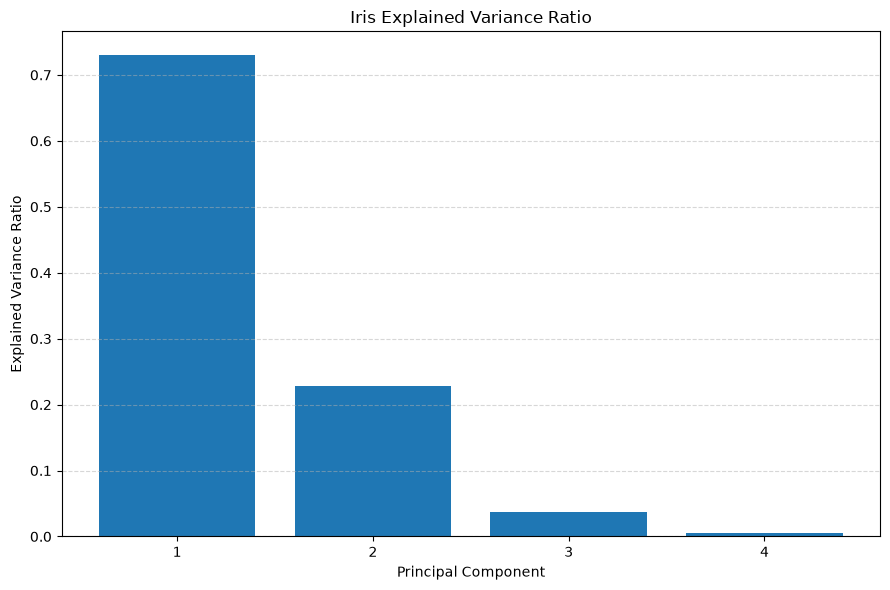

In [8]:
plt.figure()
plt.bar(range(1, len(iris_variance_ratio) + 1), iris_variance_ratio)
plt.title("Iris Explained Variance Ratio")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(iris_variance_ratio) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Iris - Question 8: Iris Cumulative Variance and 90% Threshold

The first component count whose cumulative variance reaches 90% is calculated programmatically.

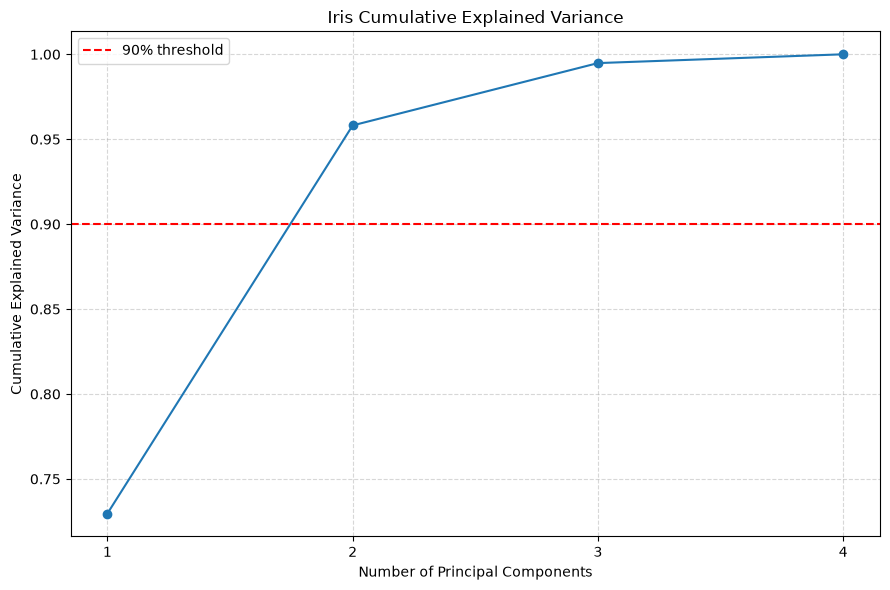

Minimum Iris components for at least 90% variance: 2
Variance retained: 0.9581320720000165


In [9]:
component_numbers = np.arange(1, len(iris_cumulative_variance) + 1)
plt.figure()
plt.plot(component_numbers, iris_cumulative_variance, marker='o')
plt.axhline(y=0.90, color='red', linestyle='--', label='90% threshold')
plt.title("Iris Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(component_numbers)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

iris_min_components_90 = np.argmax(iris_cumulative_variance >= 0.90) + 1
print("Minimum Iris components for at least 90% variance:", iris_min_components_90)
print("Variance retained:", iris_cumulative_variance[iris_min_components_90 - 1])

## Iris - Question 9: Iris Two-Component PCA

Two components reduce the standardized 4D data to two dimensions.

In [10]:
iris_pca_2 = PCA(n_components=2)
iris_pca_data = iris_pca_2.fit_transform(iris_scaled)
iris_pca_df = pd.DataFrame(iris_pca_data, columns=['PC1', 'PC2'])

print("First five rows of transformed Iris data:")
print(iris_pca_df.head())
print("Transformed data dimensions:", iris_pca_df.shape)

First five rows of transformed Iris data:
        PC1       PC2
0 -2.264703  0.480027
1 -2.080961 -0.674134
2 -2.364229 -0.341908
3 -2.299384 -0.597395
4 -2.389842  0.646835
Transformed data dimensions: (150, 2)


## Iris - Question 10: Iris Principal Component Loadings

Loadings are coefficients in `PCA.components_`. The largest absolute loading identifies the most influential original feature.

In [11]:
iris_loadings = pd.DataFrame(
    iris_pca_2.components_.T,
    index=iris.feature_names,
    columns=['PC1', 'PC2']
)
print("Iris loadings:")
print(iris_loadings)

for pc in iris_loadings.columns:
    strongest_feature = iris_loadings[pc].abs().idxmax()
    strongest_loading = iris_loadings.loc[strongest_feature, pc]
    print(f"{pc} strongest feature: {strongest_feature} (loading {strongest_loading:.4f})")

Iris loadings:
                        PC1       PC2
sepal length (cm)  0.521066  0.377418
sepal width (cm)  -0.269347  0.923296
petal length (cm)  0.580413  0.024492
petal width (cm)   0.564857  0.066942
PC1 strongest feature: petal length (cm) (loading 0.5804)
PC2 strongest feature: sepal width (cm) (loading 0.9233)


**Observation:** The displayed largest absolute loadings indicate the original features that contribute most to PC1 and PC2.

## Iris - Question 11: Iris PCA Scatter Plot

PCA coordinates are plotted with species-specific colours.

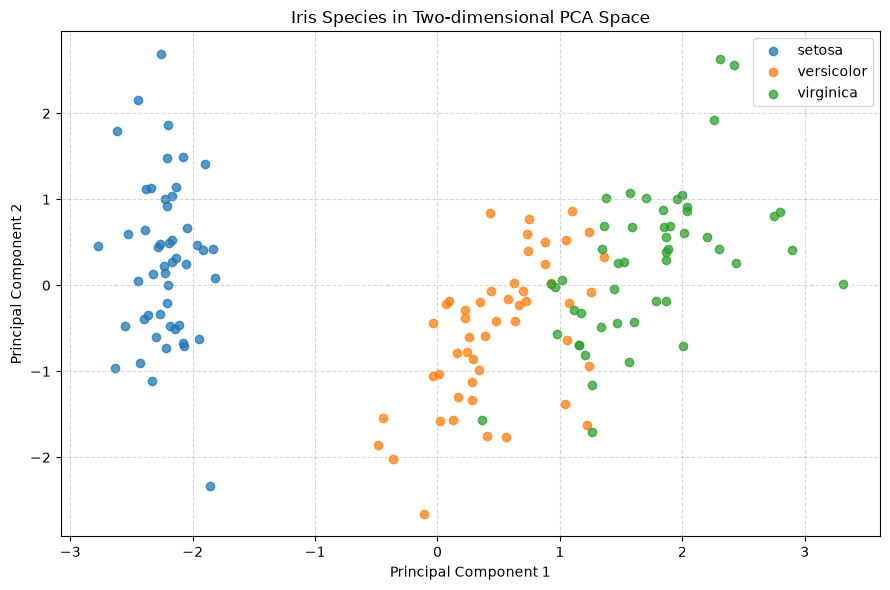

In [12]:
plt.figure()
for target_id, target_name in enumerate(iris.target_names):
    mask = iris.target == target_id
    plt.scatter(
        iris_pca_df.loc[mask, 'PC1'],
        iris_pca_df.loc[mask, 'PC2'],
        label=target_name,
        alpha=0.75
    )
plt.title("Iris Species in Two-dimensional PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Iris - Question 12: Original-Space and PCA-Space Comparison

An original two-feature scatter is a projection of the 4D data, while PC1-PC2 is an optimized projection.

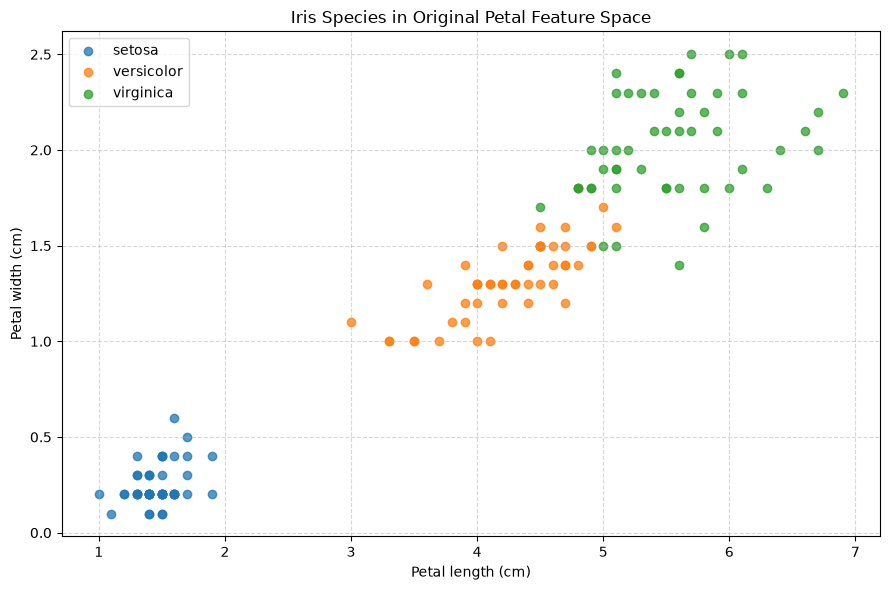

PCA uses combinations of all four standardized features for PC1 and PC2.
The PCA plot should remain mostly distinguishable, although species clusters may overlap.
PCA reduces dimensionality for visualization and does not remove every distinction between classes.


In [13]:
plt.figure()
for target_id, target_name in enumerate(iris.target_names):
    mask = iris.target == target_id
    plt.scatter(
        iris_df.loc[mask, 'petal length (cm)'],
        iris_df.loc[mask, 'petal width (cm)'],
        label=target_name,
        alpha=0.75
    )
plt.title("Iris Species in Original Petal Feature Space")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("PCA uses combinations of all four standardized features for PC1 and PC2.")
print("The PCA plot should remain mostly distinguishable, although species clusters may overlap.")
print("PCA reduces dimensionality for visualization and does not remove every distinction between classes.")

## Iris - Question 13: Variance Retained by Two Iris Components

The retained percentage is the sum of the first two explained variance ratios.

In [14]:
iris_two_component_variance = iris_pca_2.explained_variance_ratio_.sum()
iris_retained_percentage = iris_two_component_variance * 100
print(f"Percentage of variance retained with two components: {iris_retained_percentage:.2f}%")

Percentage of variance retained with two components: 95.81%


## Iris - Question 14: Reconstruct the Iris Standardized Dataset

`inverse_transform()` uses only the two retained components to approximate the standardized 4D data.

In [15]:
iris_reconstructed = iris_pca_2.inverse_transform(iris_pca_data)
iris_reconstructed_df = pd.DataFrame(iris_reconstructed, columns=iris.feature_names)

print("First five rows of the reconstructed standardized Iris dataset:")
print(iris_reconstructed_df.head())
print("Reconstructed dimensions:", iris_reconstructed_df.shape)
iris_reconstruction_error = mean_squared_error(iris_scaled, iris_reconstructed)
print("Reconstruction MSE:", iris_reconstruction_error)

First five rows of the reconstructed standardized Iris dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.998889          1.053198          -1.302707         -1.247098
1          -1.338748         -0.061923          -1.224328         -1.220572
2          -1.360961          0.321117          -1.380603         -1.358338
3          -1.423598          0.067762          -1.349224         -1.338813
4          -1.001138          1.240918          -1.371254         -1.306618
Reconstructed dimensions: (150, 4)
Reconstruction MSE: 0.04186792799998359


## Cancer - Question 1: Load and Display the Breast Cancer Dataset

The 30 feature columns and target labels are obtained from scikit-learn.

In [16]:
cancer = load_breast_cancer()
cancer_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
print("First five Breast Cancer records:")
print(cancer_df.head())

First five Breast Cancer records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst textur

## Cancer - Question 2: Cancer Dataset Dimensions and Classes

The dataset dimensions and class names are displayed without including the target in the feature data.

In [17]:
print("Total number of observations:", cancer_df.shape[0])
print("Number of features:", cancer_df.shape[1])
print("Feature names:", cancer_df.columns.tolist())
print("Target classes:", cancer.target_names.tolist())

Total number of observations: 569
Number of features: 30
Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target classes: ['malignant', 'benign']


## Cancer - Question 3: Cancer Feature Statistics and Range Differences

Features with very different ranges can dominate variance, making standardization important.

In [18]:
cancer_statistics = pd.DataFrame({
    'Mean': cancer_df.mean(),
    'Standard Deviation': cancer_df.std(),
    'Minimum': cancer_df.min(),
    'Maximum': cancer_df.max()
})
print(cancer_statistics)

cancer_ranges = cancer_df.max() - cancer_df.min()
print("\nFeatures with the 10 largest ranges:")
print(cancer_ranges.sort_values(ascending=False).head(10))

                               Mean  Standard Deviation     Minimum  \
mean radius               14.127292            3.524049    6.981000   
mean texture              19.289649            4.301036    9.710000   
mean perimeter            91.969033           24.298981   43.790000   
mean area                654.889104          351.914129  143.500000   
mean smoothness            0.096360            0.014064    0.052630   
mean compactness           0.104341            0.052813    0.019380   
mean concavity             0.088799            0.079720    0.000000   
mean concave points        0.048919            0.038803    0.000000   
mean symmetry              0.181162            0.027414    0.106000   
mean fractal dimension     0.062798            0.007060    0.049960   
radius error               0.405172            0.277313    0.111500   
texture error              1.216853            0.551648    0.360200   
perimeter error            2.866059            2.021855    0.757000   
area e

## Cancer - Question 4: Check Missing Values and Duplicates

Missing values and duplicate rows are checked directly on the feature DataFrame.

In [19]:
missing_values = cancer_df.isnull().sum()
print("Missing values per feature:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values")
print("Total missing values:", missing_values.sum())
print("Number of duplicate records:", cancer_df.duplicated().sum())

Missing values per feature:
No missing values
Total missing values: 0
Number of duplicate records: 0


## Cancer - Question 5: Standardize Cancer Features

All 30 numerical features are fitted through `StandardScaler` and converted to a DataFrame.

In [20]:
cancer_scaler = StandardScaler()
cancer_scaled = cancer_scaler.fit_transform(cancer_df)
cancer_scaled_df = pd.DataFrame(cancer_scaled, columns=cancer.feature_names)
print("First five standardized cancer records:")
print(cancer_scaled_df.head())

First five standardized cancer records:


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.097064     -2.073335        1.269934   0.984375         1.568466   
1     1.829821     -0.353632        1.685955   1.908708        -0.826962   
2     1.579888      0.456187        1.566503   1.558884         0.942210   
3    -0.768909      0.253732       -0.592687  -0.764464         3.283553   
4     1.750297     -1.151816        1.776573   1.826229         0.280372   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0          3.283515        2.652874             2.532475       2.217515   
1         -0.487072       -0.023846             0.548144       0.001392   
2          1.052926        1.363478             2.037231       0.939685   
3          3.402909        1.915897             1.451707       2.867383   
4          0.539340        1.371011             1.428493      -0.009560   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0          

## Cancer - Question 6: Cancer PCA Explained Variance Ratio

The full PCA fit computes a variance ratio for each of the 30 standardized components.

In [21]:
cancer_pca_full = PCA()
cancer_pca_full.fit(cancer_scaled)
cancer_variance_ratio = cancer_pca_full.explained_variance_ratio_

print("Explained variance ratio:")
for i, ratio in enumerate(cancer_variance_ratio, start=1):
    print(f"PC{i}: {ratio:.6f}")

Explained variance ratio:
PC1: 0.442720
PC2: 0.189712
PC3: 0.093932
PC4: 0.066021
PC5: 0.054958
PC6: 0.040245
PC7: 0.022507
PC8: 0.015887
PC9: 0.013896
PC10: 0.011690
PC11: 0.009797
PC12: 0.008705
PC13: 0.008045
PC14: 0.005234
PC15: 0.003138
PC16: 0.002662
PC17: 0.001980
PC18: 0.001754
PC19: 0.001649
PC20: 0.001039
PC21: 0.000999
PC22: 0.000915
PC23: 0.000811
PC24: 0.000602
PC25: 0.000516
PC26: 0.000273
PC27: 0.000230
PC28: 0.000053
PC29: 0.000025
PC30: 0.000004


## Cancer - Question 7: Cancer Cumulative Explained Variance Table

Cumulative variance is calculated for all 30 components.

In [22]:
cancer_cumulative_variance = np.cumsum(cancer_variance_ratio)
cancer_variance_table = pd.DataFrame({
    'Principal Component': [f'PC{i}' for i in range(1, len(cancer_variance_ratio) + 1)],
    'Explained Variance Ratio': cancer_variance_ratio,
    'Cumulative Explained Variance': cancer_cumulative_variance
})
print(cancer_variance_table.to_string())

   Principal Component  Explained Variance Ratio  Cumulative Explained Variance
0                  PC1                  0.442720                       0.442720
1                  PC2                  0.189712                       0.632432
2                  PC3                  0.093932                       0.726364
3                  PC4                  0.066021                       0.792385
4                  PC5                  0.054958                       0.847343
5                  PC6                  0.040245                       0.887588
6                  PC7                  0.022507                       0.910095
7                  PC8                  0.015887                       0.925983
8                  PC9                  0.013896                       0.939879
9                 PC10                  0.011690                       0.951569
10                PC11                  0.009797                       0.961366
11                PC12                  

## Cancer - Question 8: Cancer Explained Variance Plot

The plot identifies how rapidly additional principal components reduce in individual variance contribution.

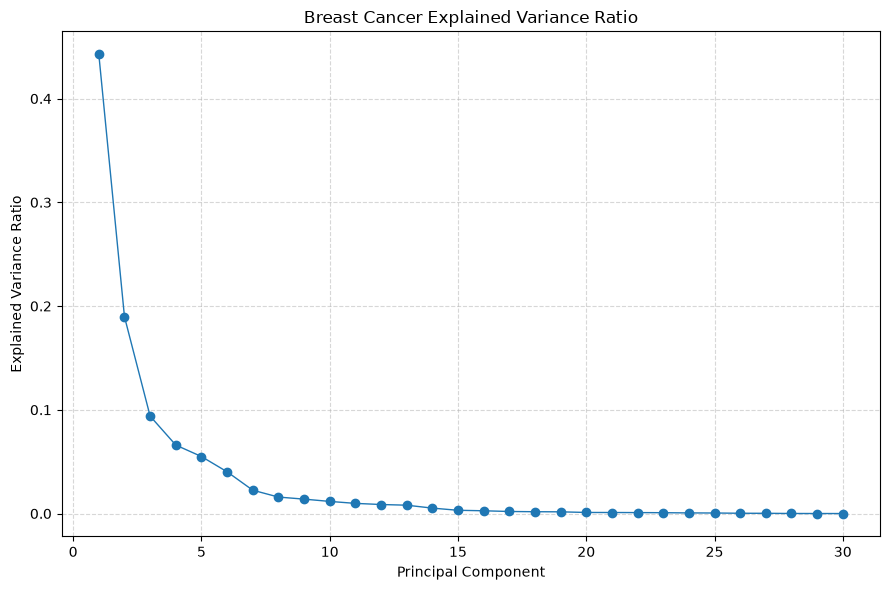

In [23]:
component_numbers_cancer = np.arange(1, len(cancer_variance_ratio) + 1)
plt.figure()
plt.plot(component_numbers_cancer, cancer_variance_ratio, marker='o', linewidth=1)
plt.title("Breast Cancer Explained Variance Ratio")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Cancer - Question 9: Cancer Cumulative Variance and 90% Threshold

The first component count whose cumulative variance is at least 90% is identified programmatically.

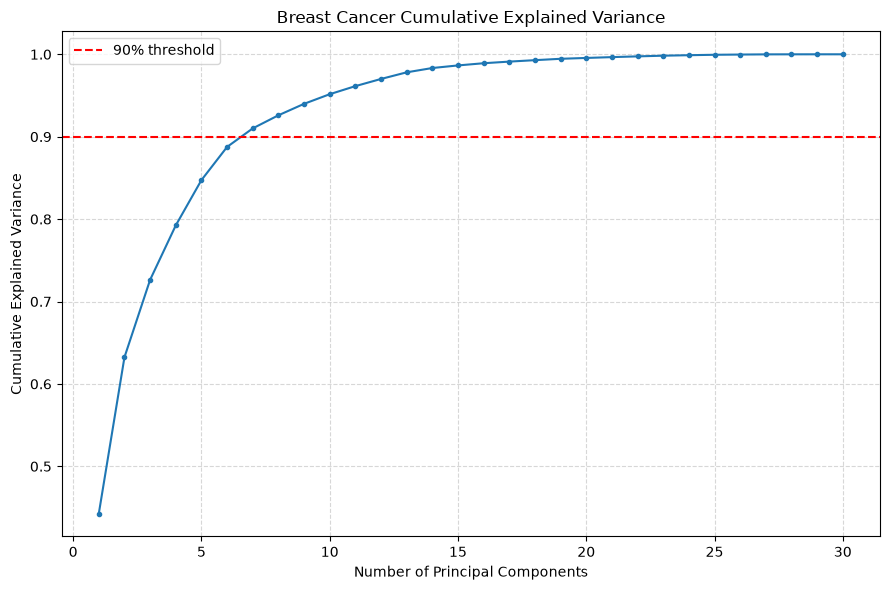

Minimum cancer components for at least 90% variance: 7
Variance retained: 0.910095300696731


In [24]:
plt.figure()
plt.plot(component_numbers_cancer, cancer_cumulative_variance, marker='o', markersize=3)
plt.axhline(y=0.90, color='red', linestyle='--', label='90% threshold')
plt.title("Breast Cancer Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

cancer_min_components_90 = np.argmax(cancer_cumulative_variance >= 0.90) + 1
print("Minimum cancer components for at least 90% variance:", cancer_min_components_90)
print("Variance retained:", cancer_cumulative_variance[cancer_min_components_90 - 1])

## Cancer - Question 10: Cancer Two-Component PCA

Only PC1 and PC2 are retained to create a 569-by-2 transformed array.

In [25]:
cancer_pca_2 = PCA(n_components=2)
cancer_pca_data = cancer_pca_2.fit_transform(cancer_scaled)
cancer_pca_df = pd.DataFrame(cancer_pca_data, columns=['PC1', 'PC2'])

print("First five rows of transformed cancer data:")
print(cancer_pca_df.head())
print("Transformed data dimensions:", cancer_pca_df.shape)

First five rows of transformed cancer data:
        PC1        PC2
0  9.192837   1.948583
1  2.387802  -3.768172
2  5.733896  -1.075174
3  7.122953  10.275589
4  3.935302  -1.948072
Transformed data dimensions: (569, 2)


## Cancer - Question 11: Cancer Principal Component Loadings

The original feature with the largest absolute coefficient is the strongest contributor to each component.

In [26]:
cancer_loadings = pd.DataFrame(
    cancer_pca_2.components_.T,
    index=cancer.feature_names,
    columns=['PC1', 'PC2']
)
print("Cancer loadings:")
print(cancer_loadings)

for pc in cancer_loadings.columns:
    strongest_feature = cancer_loadings[pc].abs().idxmax()
    strongest_loading = cancer_loadings.loc[strongest_feature, pc]
    print(f"{pc} strongest feature: {strongest_feature} (loading {strongest_loading:.4f})")

Cancer loadings:
                              PC1       PC2
mean radius              0.218902 -0.233857
mean texture             0.103725 -0.059706
mean perimeter           0.227537 -0.215181
mean area                0.220995 -0.231077
mean smoothness          0.142590  0.186113
mean compactness         0.239285  0.151892
mean concavity           0.258400  0.060165
mean concave points      0.260854 -0.034768
mean symmetry            0.138167  0.190349
mean fractal dimension   0.064363  0.366575
radius error             0.205979 -0.105552
texture error            0.017428  0.089980
perimeter error          0.211326 -0.089457
area error               0.202870 -0.152293
smoothness error         0.014531  0.204430
compactness error        0.170393  0.232716
concavity error          0.153590  0.197207
concave points error     0.183417  0.130322
symmetry error           0.042498  0.183848
fractal dimension error  0.102568  0.280092
worst radius             0.227997 -0.219866
worst texture  

## Cancer - Question 12: Cancer PCA Scatter Plot

Malignant and benign observations receive different colours in PC1-PC2 space.

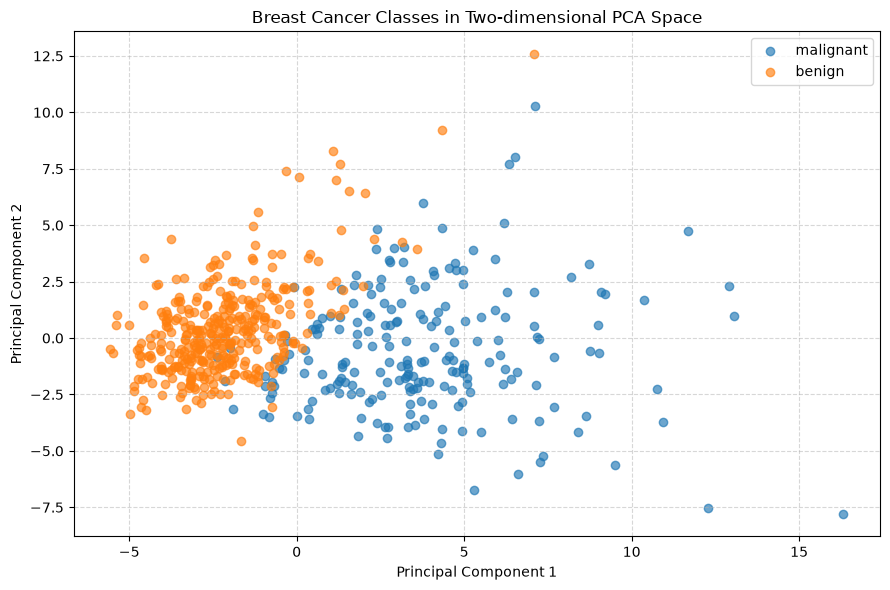

In [27]:
plt.figure()
for target_id, target_name in enumerate(['malignant', 'benign']):
    mask = cancer.target == target_id
    plt.scatter(
        cancer_pca_df.loc[mask, 'PC1'],
        cancer_pca_df.loc[mask, 'PC2'],
        label=target_name,
        alpha=0.65
    )
plt.title("Breast Cancer Classes in Two-dimensional PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Cancer - Question 13: Separation of Malignant and Benign Samples

The observation is based on the actual 2D PCA plot above.

In [28]:
cancer_two_component_variance = cancer_pca_2.explained_variance_ratio_.sum()
print("The PCA plot should be observed for cluster separation:")
print("- Clear separation means the classes occupy largely distinct regions.")
print("- Overlap means PC1 and PC2 do not perfectly distinguish every sample.")
print(f"Two principal components explain {cancer_two_component_variance * 100:.2f}% of the variance.")

The PCA plot should be observed for cluster separation:
- Clear separation means the classes occupy largely distinct regions.
- Overlap means PC1 and PC2 do not perfectly distinguish every sample.
Two principal components explain 63.24% of the variance.


## Cancer - Question 14: Variance Retained with Two Cancer Components

This percentage is computed from the two-component PCA fit.

In [29]:
cancer_retained_percentage = cancer_pca_2.explained_variance_ratio_.sum() * 100
print(f"Percentage of variance retained with PC1 and PC2: {cancer_retained_percentage:.2f}%")

Percentage of variance retained with PC1 and PC2: 63.24%


## Cancer - Question 15: Two-Component Reconstruction and MSE

`inverse_transform()` approximates the standardized 30-feature dataset. MSE is the average squared reconstruction error.

In [30]:
cancer_reconstructed_2 = cancer_pca_2.inverse_transform(cancer_pca_data)
cancer_reconstructed_2_df = pd.DataFrame(
    cancer_reconstructed_2,
    columns=cancer.feature_names
)

print("First five rows of the two-component reconstruction:")
print(cancer_reconstructed_2_df.head())
print("Reconstructed dimensions:", cancer_reconstructed_2_df.shape)
cancer_mse_2 = mean_squared_error(cancer_scaled, cancer_reconstructed_2)
print("Two-component reconstruction MSE:", cancer_mse_2)

First five rows of the two-component reconstruction:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.556644      0.837181        1.672414   1.581299         1.673460   
1     1.403909      0.472657        1.354154   1.398429        -0.360830   
2     1.506601      0.658940        1.536033   1.515610         0.617491   
3    -0.843788      0.125310       -0.590378  -0.800312         2.928081   
4     1.317018      0.524499        1.314617   1.319836         0.198572   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0          2.495685        2.492671             2.330239       1.641057   
1         -0.000988        0.390296             0.753877      -0.387352   
2          1.208728        1.416953             1.533090       0.587577   
3          3.265194        2.458809             1.500793       2.940103   
4          0.645764        0.899678             1.094268       0.172916   

   mean fractal dimension  ...  worst r

## Cancer - Question 16: 90% Reconstruction and MSE Comparison

The reconstruction uses the minimum component count reaching 90%, and its MSE is compared with the two-component MSE.

In [31]:
cancer_pca_90 = PCA(n_components=cancer_min_components_90)
cancer_pca_90_data = cancer_pca_90.fit_transform(cancer_scaled)
cancer_reconstructed_90 = cancer_pca_90.inverse_transform(cancer_pca_90_data)
cancer_mse_90 = mean_squared_error(cancer_scaled, cancer_reconstructed_90)

print("Minimum components used:", cancer_min_components_90)
print("Variance retained:", cancer_cumulative_variance[cancer_min_components_90 - 1] * 100)
print("Two-component reconstruction MSE:", cancer_mse_2)
print("90%-variance reconstruction MSE:", cancer_mse_90)
print("MSE difference (2 components minus 90% components):", cancer_mse_2 - cancer_mse_90)

if cancer_mse_90 < cancer_mse_2:
    print("Observation: The 90%-variance reconstruction has a lower reconstruction error.")
else:
    print("Observation: The two reconstructions have the same or a higher 90%-variance reconstruction error.")

Minimum components used: 7
Variance retained: 91.00953006967309
Two-component reconstruction MSE: 0.36756792348440553
90%-variance reconstruction MSE: 0.08990469930326912
MSE difference (2 components minus 90% components): 0.2776632241811364
Observation: The 90%-variance reconstruction has a lower reconstruction error.
